<a href="https://colab.research.google.com/github/A-KOStov/Evlash-Valeria-2253/blob/main/task_5_%E2%84%962.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

In [3]:
t = sp.Symbol('t')
y = sp.Function('y')
x0_val = 0.1
v0_val = 0
t_span = np.linspace(0, 10, 1000)

In [4]:
m_sym, k_sym, c_sym = sp.symbols('m k c', positive=True)
eq2 = sp.Eq(m_sym * sp.diff(y(t), t, 2) + c_sym * sp.diff(y(t), t) + k_sym * y(t), 0)
gen_sol2 = sp.dsolve(eq2)
print("Общее решение (Задача 2):")
sp.pprint(gen_sol2)

Общее решение (Задача 2):
             ⎛        ____________⎞          ⎛       ____________⎞ 
             ⎜       ╱  2         ⎟          ⎜      ╱  2         ⎟ 
           t⋅⎝-c + ╲╱  c  - 4⋅k⋅m ⎠       -t⋅⎝c + ╲╱  c  - 4⋅k⋅m ⎠ 
           ────────────────────────       ─────────────────────────
                     2⋅m                             2⋅m           
y(t) = C₁⋅ℯ                         + C₂⋅ℯ                         


In [5]:
def solve_num(c_val, k_val):
    eq_num = sp.Eq(1 * sp.diff(y(t), t, 2) + c_val * sp.diff(y(t), t) + k_val * y(t), 0)
    sol = sp.dsolve(eq_num, ics={y(0): x0_val, sp.diff(y(t), t).subs(t, 0): v0_val})
    return sol.rhs

In [6]:
print("\nПример решения для k=4, c=1:")
sp.pprint(solve_num(c_val=1, k_val=4))


Пример решения для k=4, c=1:
                                                  -t 
                                                  ───
⎛                      ⎛√15⋅t⎞          ⎛√15⋅t⎞⎞   2 
⎜0.0258198889747161⋅sin⎜─────⎟ + 0.1⋅cos⎜─────⎟⎟⋅ℯ   
⎝                      ⎝  2  ⎠          ⎝  2  ⎠⎠     


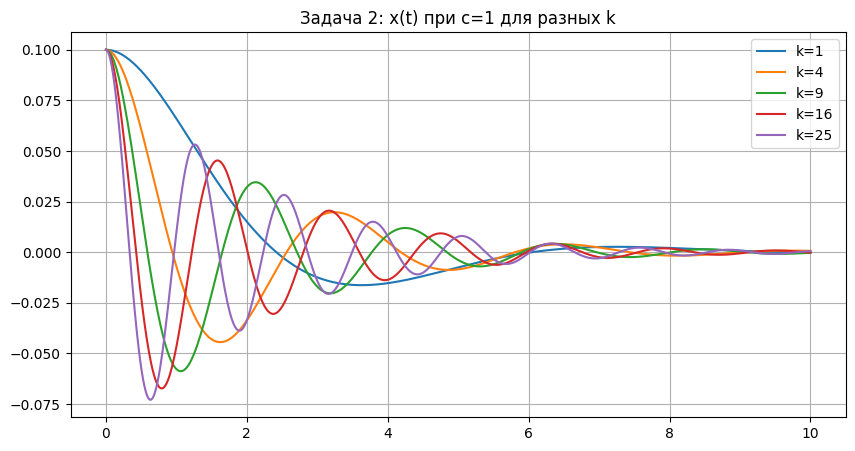

In [7]:
plt.figure(figsize=(10, 5))
for k_val in [1, 4, 9, 16, 25]:
    sol_rhs = solve_num(c_val=1, k_val=k_val)
    f_k = sp.lambdify(t, sp.re(sol_rhs), 'numpy')
    plt.plot(t_span, f_k(t_span), label=f'k={k_val}')
plt.title('Задача 2: x(t) при c=1 для разных k')
plt.legend()
plt.grid(True)
plt.show()

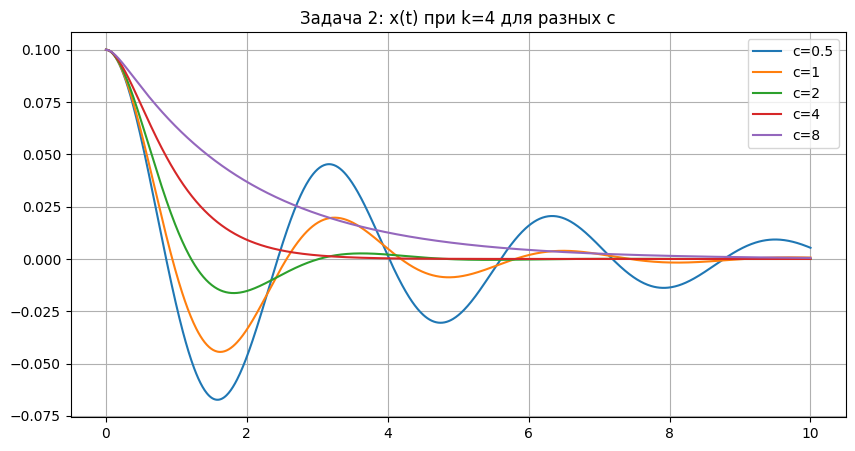

In [8]:
plt.figure(figsize=(10, 5))
for c_val in [0.5, 1, 2, 4, 8]:
    sol_rhs = solve_num(c_val=c_val, k_val=4)
    f_c = sp.lambdify(t, sp.re(sol_rhs), 'numpy')
    plt.plot(t_span, f_c(t_span), label=f'c={c_val}')
plt.title('Задача 2: x(t) при k=4 для разных c')
plt.legend()
plt.grid(True)
plt.show()

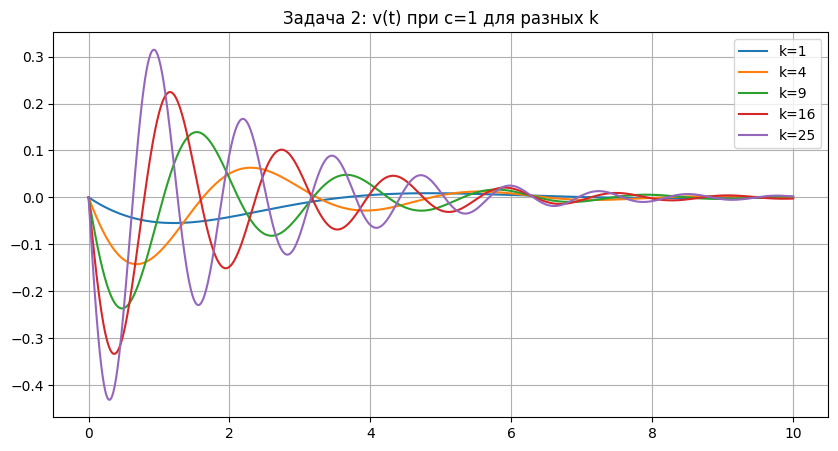

In [9]:
plt.figure(figsize=(10, 5))
for k_val in [1, 4, 9, 16, 25]:
    sol_rhs = solve_num(c_val=1, k_val=k_val)
    v_rhs = sp.diff(sol_rhs, t)
    f_vk = sp.lambdify(t, sp.re(v_rhs), 'numpy')
    plt.plot(t_span, f_vk(t_span), label=f'k={k_val}')
plt.title('Задача 2: v(t) при c=1 для разных k')
plt.legend()
plt.grid(True)
plt.show()

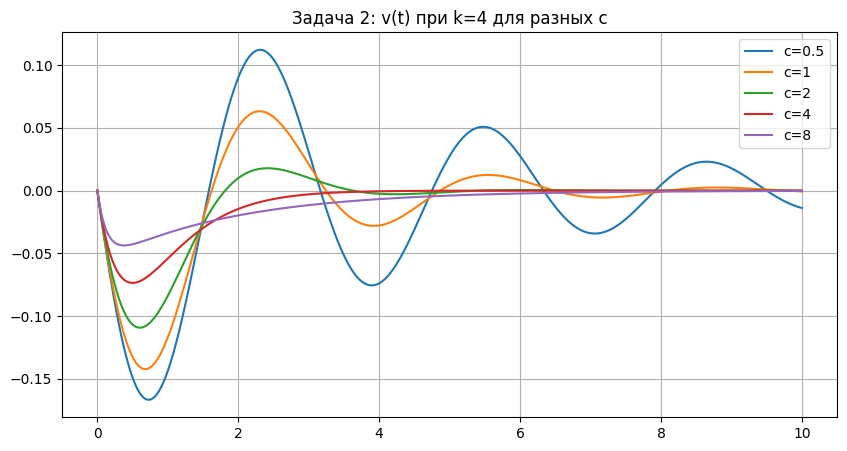

In [10]:
plt.figure(figsize=(10, 5))
for c_val in [0.5, 1, 2, 4, 8]:
    sol_rhs = solve_num(c_val=c_val, k_val=4)
    v_rhs = sp.diff(sol_rhs, t)
    f_vc = sp.lambdify(t, sp.re(v_rhs), 'numpy')
    plt.plot(t_span, f_vc(t_span), label=f'c={c_val}')
plt.title('Задача 2: v(t) при k=4 для разных c')
plt.legend()
plt.grid(True)
plt.show()

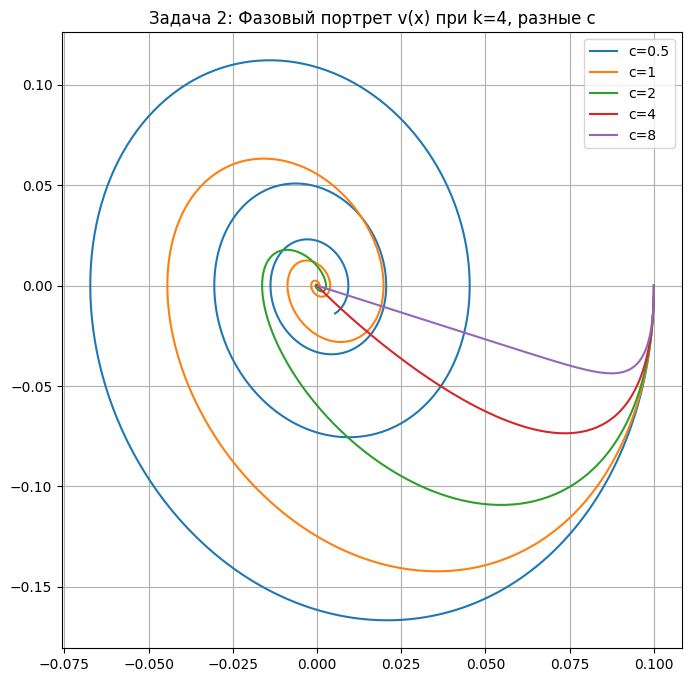

In [11]:
plt.figure(figsize=(8, 8))
for c_val in [0.5, 1, 2, 4, 8]:
    sol_rhs = solve_num(c_val=c_val, k_val=4)
    v_rhs = sp.diff(sol_rhs, t)
    x_arr = sp.lambdify(t, sp.re(sol_rhs), 'numpy')(t_span)
    v_arr = sp.lambdify(t, sp.re(v_rhs), 'numpy')(t_span)
    plt.plot(x_arr, v_arr, label=f'c={c_val}')
plt.title('Задача 2: Фазовый портрет v(x) при k=4, разные c')
plt.legend()
plt.grid(True)
plt.show()